# Manual Audit

How well a metric ranks summaries for a human auditor: Spearman's rank
correlation between a summary's score and the number of aspects modified in it
(Table 3), and the yield at a fixed review budget - the share of a platform's
summaries that are both modified and among those a human reviews (Fig. 5).


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def locate_project_root():
    override = os.environ.get("DECEPTION_PROJECT_ROOT")
    if override:
        return Path(override).expanduser().resolve()
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "experiment.yaml").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find experiment.yaml. Start Jupyter inside the project or "
        "set DECEPTION_PROJECT_ROOT."
    )


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from score_analysis import SUMMARY_CONDITION_LABELS, load_score_analysis, metric_order

OUTPUT_ROOT = PROJECT_ROOT / "results" / "figures"

# The generated panel only; the hand-written edits are analysed in plot_scores.
score_long = load_score_analysis(project_root=PROJECT_ROOT, score_sets=("main",))
# Lower raw values are more suspicious for every metric; flip them so higher
# means more faithful, without rescaling.
score_long["faithfulness_score"] = -score_long["anomaly_score"]

# One row per record: its metadata and one column per metric.
record_metadata = score_long.drop_duplicates("record_id", keep="last")[
    ["record_id", "product_id", "summary_condition", "family", "condition", "severity"]
]
score_wide = score_long.pivot_table(
    index="record_id", columns="metric", values="faithfulness_score", aggfunc="last",
).reset_index()
df = record_metadata.merge(score_wide, on="record_id", how="inner")
df["summary_type"] = df["summary_condition"]
# The two one-aspect directions (`..._count1_advantageous` and
# `..._disadvantageous`) form one condition; faithful summaries are `source`.
df["bias_type"] = np.where(
    df["family"].eq("faithful"),
    "source",
    df["condition"].str.replace(r"_count1_(advantageous|disadvantageous)$", "_count1", regex=True),
)

AVAILABLE_METRICS = [metric for metric in metric_order(score_long)
                     if metric in df.columns and df[metric].notna().any()]
STYLE_LABELS = {style: SUMMARY_CONDITION_LABELS.get(style, style.replace("_", " ").title())
                for style in sorted(df["summary_type"].unique())}


# Spearman's Rank Correlation

In [2]:
# ============================================================================
# Spearman rank correlation between a summary's score and the number of
# aspects modified in it: 0 for the unmodified summary, 1-4 for its
# modifications. Every summary counts once: the unmodified summary and each of
# its modifications, both directions of the one-aspect modification included.
# ============================================================================

from scipy.stats import spearmanr

# Modification families carrying a 1-4 aspect ladder.
SPEARMAN_FAMILY_LABELS = {
    "factual_error":   "Factual Errors",
    "aspect_deletion": "Aspect Deletions",
    "quantifier_swap": "Quantifier Swaps",
}
SPEARMAN_FAMILIES = list(SPEARMAN_FAMILY_LABELS)
SPEARMAN_TABLE_METRICS = [("geval_consistency", "Consistency"),
                          ("geval_relevance", "Relevance")]

_results = []
for family in SPEARMAN_FAMILIES:
    for metric in AVAILABLE_METRICS:
        rows = df[df["family"].isin(["faithful", family])].dropna(subset=[metric])
        scores = pd.DataFrame({"n_errors": rows["severity"].astype(float), "score": rows[metric]})
        rho, p = spearmanr(scores["n_errors"], scores["score"])
        by_level = scores.groupby("n_errors")["score"]
        _results.append({
            "family": family,
            "metric": metric,
            "n_rows": len(scores),
            "spearman_rho": round(float(rho), 4),
            "p_value": float(p),
            "n_errors_levels": sorted(scores["n_errors"].unique().tolist()),
            "mean_score_by_level": by_level.mean().round(3).to_dict(),
            "n_by_level": by_level.size().to_dict(),
        })

spearman_results = pd.DataFrame(_results)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 220)
print(spearman_results.to_string(index=False))


# --- 5. LaTeX table -------------------------------------------------------

def _stars(p):
    """Significance markers, conventional thresholds."""
    if p is None or not np.isfinite(p):
        return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def spearman_latex_table(results):
    """The table as it goes into the paper."""
    used = set()
    body = []

    for family in SPEARMAN_FAMILIES:
        cells = []
        for metric, _ in SPEARMAN_TABLE_METRICS:
            row = results[(results["family"] == family)
                          & (results["metric"] == metric)]
            if row.empty or not np.isfinite(row["spearman_rho"].iloc[0]):
                cells.append("--")
                continue
            rho = float(row["spearman_rho"].iloc[0])
            mark = _stars(float(row["p_value"].iloc[0]))
            used.add(mark)
            cells.append(f"${rho:.2f}$" + mark)
        body.append(f"{SPEARMAN_FAMILY_LABELS.get(family, family.title())} & "
                    + " & ".join(cells) + r" \\")

    # Only explain the markers that actually appear.
    legend = {"***": r"*** indicates $p < 0.001$",
              "**": r"** indicates $p < 0.01$",
              "*": r"* indicates $p < 0.05$"}
    notes = [legend[m] for m in ("***", "**", "*") if m in used]
    note = (", where " + " and ".join(notes)) if notes else ""

    names = [SPEARMAN_FAMILY_LABELS.get(f, f).lower() for f in SPEARMAN_FAMILIES]
    families = (names[0] if len(names) == 1
                else " and ".join(names) if len(names) == 2
                else ", ".join(names[:-1]) + ", and " + names[-1])
    headers = " & ".join(rf"\textbf{{{label}}}"
                         for _, label in SPEARMAN_TABLE_METRICS)

    return "\n".join([
        r"\begin{table}[h!]",
        r"\centering",
        (r"\caption{Spearman's Rank coefficients between increasing numbers of "
         f"{families} for the "
         + " and ".join(label for _, label in SPEARMAN_TABLE_METRICS)
         + f" metrics{note}}}"),
        r"\label{tab:spearman}",
        r"\begin{tabular}{l" + "c" * len(SPEARMAN_TABLE_METRICS) + "}",
        r"\toprule",
        r"\textbf{Spearman's Rho} & " + headers + r" \\",
        r"\midrule",
        *body,
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}",
    ])


SPEARMAN_TABLE = spearman_latex_table(spearman_results)
SPEARMAN_TABLE_PATH = PROJECT_ROOT / "results" / "tables" / "spearman.tex"
SPEARMAN_TABLE_PATH.parent.mkdir(parents=True, exist_ok=True)
SPEARMAN_TABLE_PATH.write_text(SPEARMAN_TABLE + "\n", encoding="utf-8")
print(f"\nSaved: {os.path.relpath(SPEARMAN_TABLE_PATH, PROJECT_ROOT)}")

         family            metric  n_rows  spearman_rho      p_value           n_errors_levels                                          mean_score_by_level                                              n_by_level
  factual_error geval_consistency   14748       -0.7875 0.000000e+00 [0.0, 1.0, 2.0, 3.0, 4.0] {0.0: 4.909, 1.0: 2.639, 2.0: 1.964, 3.0: 1.757, 4.0: 1.603} {0.0: 2640, 1.0: 4993, 2.0: 2412, 3.0: 2384, 4.0: 2319}
  factual_error   geval_relevance   14748       -0.7752 0.000000e+00 [0.0, 1.0, 2.0, 3.0, 4.0] {0.0: 4.955, 1.0: 3.196, 2.0: 2.205, 3.0: 1.785, 4.0: 1.518} {0.0: 2640, 1.0: 4993, 2.0: 2412, 3.0: 2384, 4.0: 2319}
aspect_deletion geval_consistency   14414       -0.1617 5.448426e-85 [0.0, 1.0, 2.0, 3.0, 4.0] {0.0: 4.909, 1.0: 4.882, 2.0: 4.864, 3.0: 4.844, 4.0: 4.829} {0.0: 2640, 1.0: 4805, 2.0: 2362, 3.0: 2334, 4.0: 2273}
aspect_deletion   geval_relevance   14414       -0.4550 0.000000e+00 [0.0, 1.0, 2.0, 3.0, 4.0] {0.0: 4.955, 1.0: 4.901, 2.0: 4.816, 3.0: 4.706, 4.0: 4.5

# Yield at fixed budget

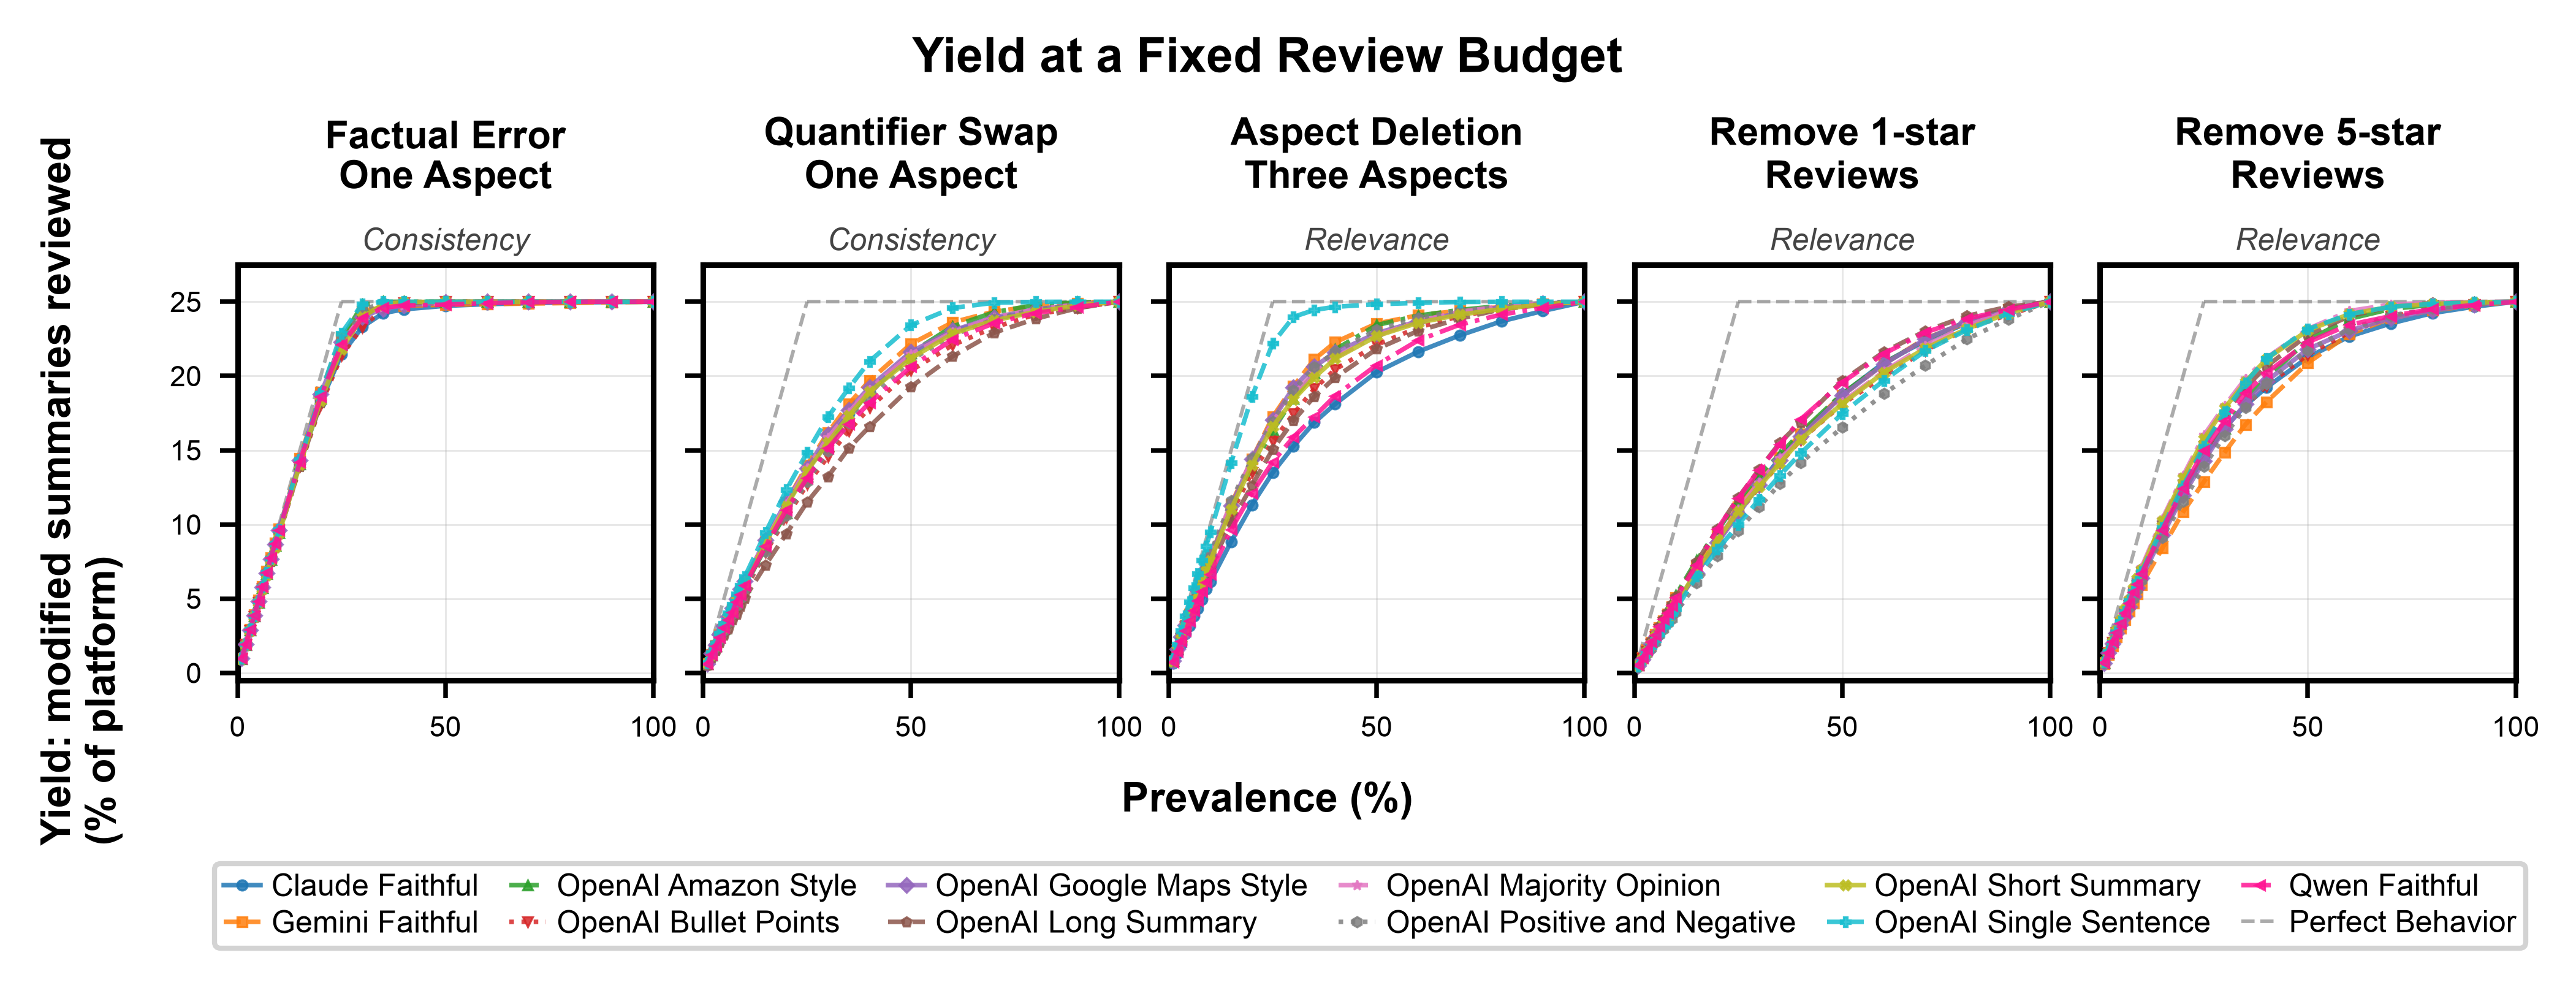

  Saved: manual_detection_rate_at_25pct_conditions.pdf  (5 conditions in one figure)


In [3]:
# ============================================================================
# Yield at a fixed review budget
#
# An auditor reads the lowest-scoring 25% of a platform's 100 summaries. The
# yield is the share of the whole platform that is both modified and read,
# TP / n_total: under perfect ranking it equals the prevalence up to the
# budget and stays at 25% after. Simulated per summarization style, with each
# condition scored by the metric that detects it - Relevance for aspect deletions and
# review removal, Consistency otherwise.
# ============================================================================

REVIEW_FRACTION      = 0.25
SAMPLES_PER_PLATFORM = 100
N_EVAL_ITERATIONS    = 1_000
RANDOM_STATE         = 42
PREVALENCE_LEVELS = [
    1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
    15, 20, 25, 30, 35, 40, 50, 60, 70, 80, 90, 100,
]

# One representative condition per modification family, as in Fig. 4.
AUDIT_CONDITIONS = [
    "factual_error_count1",
    "quantifier_swap_count1",
    "aspect_deletion_count3",
    "remove_100pct_one_star",
    "remove_100pct_five_star",
]
AUDIT_CONDITION_LABELS = {
    "factual_error_count1":     "Factual Error\nOne Aspect",
    "quantifier_swap_count1":       "Quantifier Swap\nOne Aspect",
    "aspect_deletion_count3":             "Aspect Deletion\nThree Aspects",
    "remove_100pct_one_star":  "Remove 1-star\nReviews",
    "remove_100pct_five_star": "Remove 5-star\nReviews",
}
BIAS_METRIC_MAP = {
    condition: ("geval_relevance" if condition.startswith(("aspect_deletion", "remove_"))
                else "geval_consistency")
    for condition in AUDIT_CONDITIONS
}
AUDIT_PANELS_PER_ROW = len(AUDIT_CONDITIONS)
AUDIT_TEXTWIDTH_IN = 7.0          # ACM two-column text width
AUDIT_METRIC_WORD = {"geval_consistency": "Consistency",
                     "geval_relevance": "Relevance"}

COLORS     = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b',
              '#e377c2','#7f7f7f','#bcbd22','#17becf','#ff1493','#00ff00']
MARKERS    = ['o','s','^','v','D','p','*','h','X','P','<','>']
LINESTYLES = ['-','--','-.',':','-','--','-.',':','-','--','-.',':']
PLOT_STYLE = {
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 12, 'axes.titlesize': 14, 'axes.labelsize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 10,
    'figure.titlesize': 16, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'figure.dpi': 600,
    'axes.linewidth': 1.1, 'axes.edgecolor': 'black',
    'xtick.major.width': 0.9, 'ytick.major.width': 0.9,
    'xtick.color': 'black', 'ytick.color': 'black',
}


def sample_yield_at_k(scores, labels, k, n_total):
    """Yield = TP / n_total for the k samples with the LOWEST scores."""
    idx = np.argpartition(scores, k - 1)[:k]
    return float(labels[idx].sum() / n_total)


def evaluate_yield(prevalence, faithful_scores, deceptive_scores, seed):
    """Mean yield over N_EVAL_ITERATIONS simulated platforms at this prevalence."""
    rng = np.random.default_rng(seed)
    n_total = SAMPLES_PER_PLATFORM
    k = max(1, int(round(n_total * REVIEW_FRACTION)))
    n_dec = int(n_total * prevalence / 100.0)
    n_fai = n_total - n_dec

    rates = np.empty(N_EVAL_ITERATIONS)
    for i in range(N_EVAL_ITERATIONS):
        scores = np.empty(n_total)
        labels = np.zeros(n_total, dtype=np.int8)
        if n_dec > 0:
            scores[:n_dec] = deceptive_scores[rng.integers(0, len(deceptive_scores), n_dec)]
            labels[:n_dec] = 1
        if n_fai > 0:
            scores[n_dec:] = faithful_scores[rng.integers(0, len(faithful_scores), n_fai)]
        rates[i] = sample_yield_at_k(scores, labels, k, n_total)
    return float(rates.mean())


def run_per_style_yield(df, bias_type, score_column):
    """Yield at every prevalence, per summarization style, for one condition."""
    faithful = df[df['bias_type'].eq('source')]
    deceptive = df[df['bias_type'].eq(bias_type)]
    styles = sorted(set(faithful['summary_type']) & set(deceptive['summary_type']))

    rows = []
    for style_idx, style in enumerate(styles, 1):
        fai_scores = faithful.loc[faithful['summary_type'] == style, score_column].to_numpy(dtype=np.float64)
        dec_scores = deceptive.loc[deceptive['summary_type'] == style, score_column].to_numpy(dtype=np.float64)
        seed = RANDOM_STATE + style_idx * 1000
        for prev in PREVALENCE_LEVELS:
            rows.append({"bias_type": bias_type, "metric": score_column, "style": style,
                         "prevalence": prev,
                         "yield": evaluate_yield(prev, fai_scores, dec_scores, seed + prev)})
    return pd.DataFrame(rows)


def _fmt_style(s):
    return STYLE_LABELS.get(str(s), str(s).replace('_', ' ').title())


def plot_all_bias(all_results, bias_metric_map):
    """Every condition in one figure, with a single shared legend."""
    plt.rcdefaults()
    plt.rcParams.update(PLOT_STYLE)
    panels = [(bias, all_results[bias]) for bias in AUDIT_CONDITIONS
              if all_results.get(bias) is not None and len(all_results[bias]) > 0]
    if not panels:
        print("  No results to plot.")
        return

    n_cols = min(AUDIT_PANELS_PER_ROW, len(panels))
    n_rows = -(-len(panels) // n_cols)
    cutoff = 100 * REVIEW_FRACTION
    y_max_pct = cutoff * 1.10

    # Margins in inches: as fractions they scale with the figure, so a
    # five-row version would leave inches of blank space where a one-row
    # version needs a fraction of one.
    # Square panels, as in the Spearman figure: the leftover width sets the
    # panel size and the height follows, so the boxes stay square however
    # many conditions are shown.
    top_in, bottom_in = 0.72, 0.82
    left, right, wspace, hspace = 0.10, 0.985, 0.12, 0.34
    panel_in = ((right - left) * AUDIT_TEXTWIDTH_IN
                / (n_cols + (n_cols - 1) * wspace))
    fig_h = (panel_in * n_rows + panel_in * hspace * (n_rows - 1)
             + top_in + bottom_in)

    fig, axes = plt.subplots(
        n_rows, n_cols, sharex=True, sharey=True,
        figsize=(AUDIT_TEXTWIDTH_IN, fig_h),
        gridspec_kw={'hspace': hspace, 'wspace': wspace,
                     'top': 1 - top_in / fig_h, 'bottom': bottom_in / fig_h,
                     'left': left, 'right': right},
    )
    axes = np.atleast_1d(axes).ravel()
    handles = {}

    for ax, (bias_type, res) in zip(axes, panels):
        for i, style in enumerate(sorted(res['style'].unique())):
            sub = res[res['style'] == style].sort_values('prevalence')
            line, = ax.plot(sub['prevalence'], sub['yield'] * 100,
                            color=COLORS[i % len(COLORS)],
                            marker=MARKERS[i % len(MARKERS)],
                            linestyle=LINESTYLES[i % len(LINESTYLES)],
                            markersize=2.0, linewidth=0.9, alpha=0.85,
                            markeredgewidth=0.4, zorder=3)
            handles.setdefault(_fmt_style(style), line)

        # Perfect behaviour: linear until the budget is exhausted, flat after.
        prev_linear = np.linspace(0, cutoff, 200)
        reference, = ax.plot(prev_linear, prev_linear, color='#888888',
                             linestyle='--', linewidth=0.7, alpha=0.7, zorder=2)
        ax.hlines(y=cutoff, xmin=cutoff, xmax=100, color='#888888',
                  linestyle='--', linewidth=0.7, alpha=0.7, zorder=2)
        handles.setdefault('Perfect Behavior', reference)

        ax.set_box_aspect(1)
        ax.grid(True, which='major', linestyle='-', linewidth=0.35,
                alpha=0.30, zorder=1)
        ax.set_xlim(0, 100)
        ax.set_ylim(-0.5, y_max_pct)
        ax.set_xticks([0, 50, 100])
        ax.set_yticks([0, 5, 10, 15, 20, 25])
        ax.tick_params(labelsize=5.5)
        label = AUDIT_CONDITION_LABELS[bias_type]
        metric_word = AUDIT_METRIC_WORD.get(bias_metric_map[bias_type],
                                            bias_metric_map[bias_type])
        # The metric sits under the condition name in the same style the
        # aggregate grid in market_monitoring.ipynb uses: smaller, italic and
        # grey rather than bold, so the condition reads as the heading and
        # the metric as an annotation on it.
        ax.set_title(label, fontsize=7.5, fontweight='bold', pad=15,
                     linespacing=1.2)
        ax.text(0.5, 1.02, metric_word, transform=ax.transAxes,
                ha='center', va='bottom', fontsize=6.0, style='italic',
                color='#444444')

    for ax in axes[len(panels):]:
        ax.set_axis_off()

    xlabel = fig.supxlabel('Prevalence (%)', fontsize=8,
                           fontweight='bold', y=0.44 / fig_h)
    ylabel = fig.supylabel('Yield: modified summaries reviewed\n'
                           '(% of platform)',
                           fontsize=8, fontweight='bold', x=0.022)
    title = fig.suptitle(
        "Yield at a Fixed Review Budget",
        fontsize=9.5, fontweight='bold', y=1 - 0.10 / fig_h)

    # One legend for the whole figure, spread horizontally under the panels.
    legend = fig.legend(handles.values(), handles.keys(),
                        loc='lower center', bbox_to_anchor=(0.54, 0.05 / fig_h),
                        ncol=6, fontsize=6, framealpha=0.85,
                        borderpad=0.3, handlelength=1.2, handletextpad=0.35,
                        columnspacing=1.0, labelspacing=0.25,
                        edgecolor='#cccccc')

    out_dir = str(OUTPUT_ROOT / "manual_review_yield")
    os.makedirs(out_dir, exist_ok=True)
    fname = f"manual_detection_rate_at_{int(100 * REVIEW_FRACTION)}pct_conditions"
    for ext in ('pdf', 'png'):
        plt.savefig(os.path.join(out_dir, f"{fname}.{ext}"), dpi=600,
                    bbox_inches='tight',
                    bbox_extra_artists=[legend, title, xlabel, ylabel],
                    pad_inches=0.03)
    plt.show()
    plt.close(fig)
    print(f"  Saved: {fname}.pdf  ({len(panels)} conditions in one figure)")


all_results = {condition: run_per_style_yield(df, condition, BIAS_METRIC_MAP[condition])
               for condition in AUDIT_CONDITIONS}
plot_all_bias(all_results, BIAS_METRIC_MAP)